In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 한글 폰트 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_columns', None)

DATA_PATH = r'C:\Users\kjlee\도심관련\지하철관련\metro_usage_202607071800.csv'

In [2]:
df = pd.read_csv(
    DATA_PATH,
    dtype={'station_id': str, 'ticket_type': str},
    parse_dates=['bording_date'],
)

print('shape:', df.shape)
print()
print(df.dtypes)
df.head()

shape: (965734, 9)

id                       int64
analy_type                 str
dest                   float64
bording_date    datetime64[us]
ticket_type                str
bording_type               str
qty                      int64
station_id                 str
bording_time               str
dtype: object


,id,analy_type,dest,bording_date,ticket_type,bording_type,qty,station_id,bording_time
0,2350899,60min,NaN,2024-01-01,32,승차,5,1104,04:00:00
1,2350900,60min,NaN,2024-01-01,32,하차,5,1104,04:00:00
2,2350901,60min,NaN,2024-01-01,32,승차,2,1104,05:00:00
3,2350902,60min,NaN,2024-01-01,32,하차,6,1104,05:00:00
4,2350903,60min,NaN,2024-01-01,보통권,승차,14,1104,05:00:00


In [3]:
print('기간        :', df.bording_date.min().date(), '~', df.bording_date.max().date(),
      f'({df.bording_date.dt.date.nunique()}일)')
print('역          :', df.station_id.unique())
print('analy_type  :', df.analy_type.unique())
print('bording_type:', df.bording_type.unique())
print('ticket_type :', df.ticket_type.unique())
print('dest 결측률 :', f'{df.dest.isna().mean():.0%}')
print()
print('결측치:')
print(df.isna().sum())
print()
print('qty 분포:')
print(df.qty.describe())

기간        : 2024-01-01 ~ 2026-01-01 (732일)
역          : <StringArray>
['1104']
Length: 1, dtype: str
analy_type  : <StringArray>
['60min', '30min', '15min', '5min']
Length: 4, dtype: str
bording_type: <StringArray>
['승차', '하차']
Length: 2, dtype: str
ticket_type : <StringArray>
['32', '보통권', '22', '128', '160']
Length: 5, dtype: str
dest 결측률 : 100%

결측치:
id                   0
analy_type           0
dest            965734
bording_date         0
ticket_type          0
bording_type         0
qty                  0
station_id           0
bording_time         0
dtype: int64

qty 분포:
count    965734.000000
mean         67.378168
std         127.070073
min           1.000000
25%           4.000000
50%          17.000000
75%          74.000000
max        2051.000000
Name: qty, dtype: float64


In [4]:
# 해상도별 총합·행수·기간 비교
summary = df.groupby('analy_type').agg(
    rows=('qty', 'size'),
    qty_sum=('qty', 'sum'),
    date_min=('bording_date', 'min'),
    date_max=('bording_date', 'max'),
)
print(summary)
print()
print('총합 일치 여부:', summary.qty_sum.nunique() == 1)

              rows   qty_sum   date_min   date_max
analy_type                                        
15min       225862  16267347 2024-01-01 2026-01-01
30min       122007  16267347 2024-01-01 2026-01-01
5min        550245  16267347 2024-01-01 2026-01-01
60min        67620  16267347 2024-01-01 2026-01-01

총합 일치 여부: True


In [5]:
sample = df[
    (df.bording_date == '2024-03-04')
    & (df.bording_type == '승차')
    & (df.bording_time >= '18:00:00')
    & (df.bording_time < '19:00:00')
]

for t in ['60min', '30min', '15min', '5min']:
    s = sample[sample.analy_type == t].sort_values('bording_time')
    detail = ' | '.join(f'{r.bording_time[:5]}={r.qty}' for r in s.itertuples())
    print(f'{t:6s}  {detail}   => 합계 {s.qty.sum()}')

60min   18:00=1 | 18:00=49 | 18:00=847   => 합계 897
30min   18:00=1 | 18:00=26 | 18:00=529 | 18:30=23 | 18:30=318   => 합계 897
15min   18:00=11 | 18:00=267 | 18:15=1 | 18:15=15 | 18:15=262 | 18:30=9 | 18:30=177 | 18:45=14 | 18:45=141   => 합계 897
5min    18:00=2 | 18:00=65 | 18:05=5 | 18:05=77 | 18:10=4 | 18:10=125 | 18:15=1 | 18:15=8 | 18:15=81 | 18:20=2 | 18:20=94 | 18:25=87 | 18:25=5 | 18:30=4 | 18:30=41 | 18:35=2 | 18:35=86 | 18:40=3 | 18:40=50 | 18:45=6 | 18:45=50 | 18:50=5 | 18:50=51 | 18:55=3 | 18:55=40   => 합계 897


In [6]:
# 5min이 원천 데이터 — 나머지 해상도는 사전집계 캐시이므로 제거
raw = df[df.analy_type == '5min'].drop(columns=['dest', 'analy_type', 'id']).copy()
print('5min 데이터:', raw.shape)
raw.head()

5min 데이터: (550245, 6)


,bording_date,ticket_type,bording_type,qty,station_id,bording_time
415489,2024-01-01,32,승차,5,1104,04:35:00
415490,2024-01-01,32,하차,5,1104,04:35:00
415491,2024-01-01,보통권,승차,1,1104,05:10:00
415492,2024-01-01,보통권,승차,2,1104,05:20:00
415493,2024-01-01,보통권,승차,1,1104,05:25:00


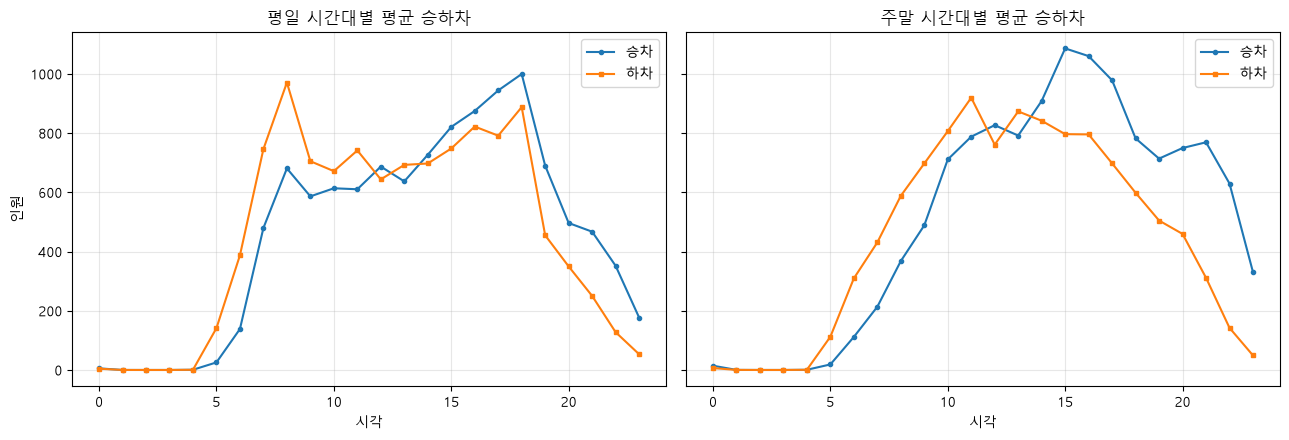

In [7]:
tmp = raw.copy()
tmp['hour'] = tmp.bording_time.str[:2].astype(int)
tmp['is_weekend'] = tmp.bording_date.dt.dayofweek >= 5

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, wend, title in [(axes[0], False, '평일'), (axes[1], True, '주말')]:
    sub = tmp[tmp.is_weekend == wend]
    ndays = sub.bording_date.nunique()
    g = sub.groupby(['hour', 'bording_type']).qty.sum().unstack() / ndays
    g = g.reindex(range(24), fill_value=0)
    ax.plot(g.index, g['승차'], marker='o', ms=3, label='승차')
    ax.plot(g.index, g['하차'], marker='s', ms=3, label='하차')
    ax.set_title(f'{title} 시간대별 평균 승하차')
    ax.set_xlabel('시각'); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('인원')
plt.tight_layout(); plt.show()

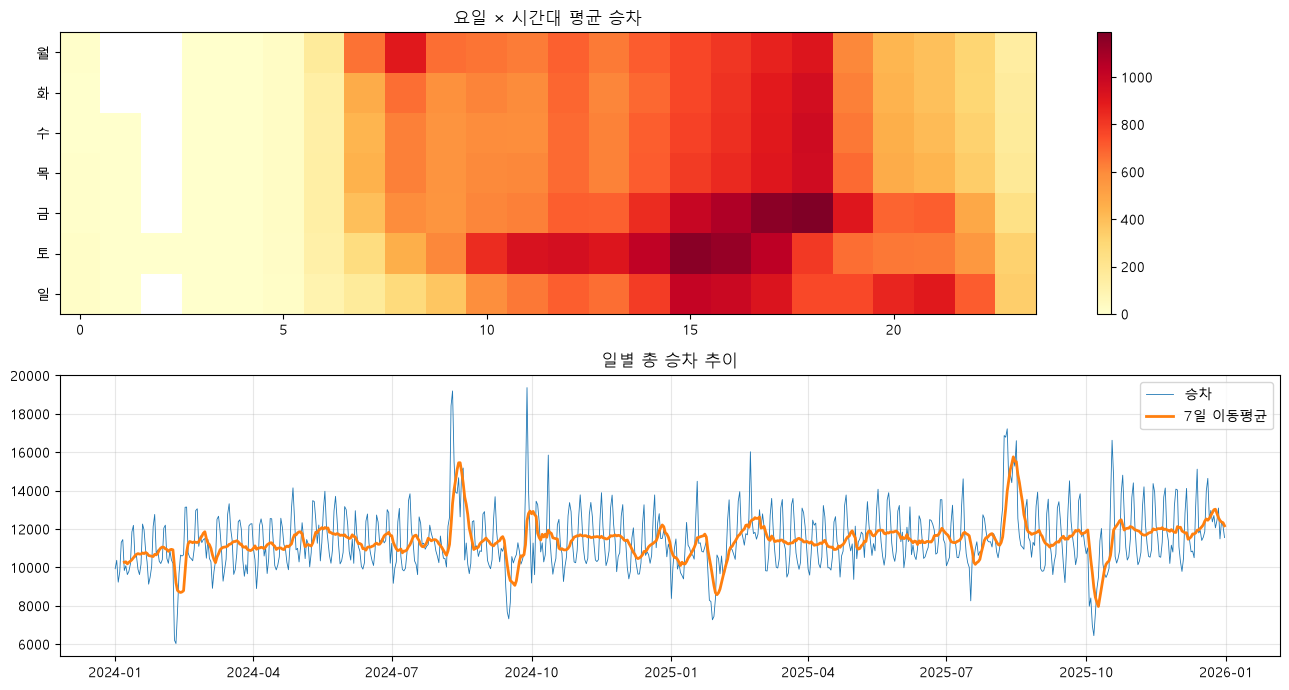

In [8]:
tmp['dow'] = tmp.bording_date.dt.dayofweek

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

# 요일×시간 히트맵 (승차)
piv = tmp[tmp.bording_type == '승차'].groupby(['dow', 'hour']).qty.sum().unstack()
piv = piv.reindex(columns=range(24), fill_value=0).div(tmp.groupby('dow').bording_date.nunique(), axis=0)
im = axes[0].imshow(piv, aspect='auto', cmap='YlOrRd')
axes[0].set_yticks(range(7)); axes[0].set_yticklabels(['월','화','수','목','금','토','일'])
axes[0].set_title('요일 × 시간대 평균 승차'); plt.colorbar(im, ax=axes[0])

# 일별 추이
daily = tmp.groupby(['bording_date', 'bording_type']).qty.sum().unstack()
axes[1].plot(daily.index, daily['승차'], lw=.6, label='승차')
axes[1].plot(daily.index, daily['승차'].rolling(7).mean(), lw=2, label='7일 이동평균')
axes[1].set_title('일별 총 승차 추이'); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()